# Example notebook

In [1]:
import scanpy as sc
import squidpy as sq
import diffsvg as dvg

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/HiWi/both_conditions_5_7_without_noise.h5ad")

In [3]:
sq.tl.var_by_distance(
    adata, cluster_key="Dentate_Gyrus", groups="anchor", library_key="condition", covariates="condition"
)

In [4]:
adata.obsm["design_matrix"]

,Dentate_Gyrus,condition,anchor,anchor_raw
aaabncdp-1,outside,wildtype,0.333524,1321.582997
aaacifle-1,outside,wildtype,0.331894,1315.123685
aaadpmhm-1,outside,wildtype,0.350915,1390.492982
aaaegbnf-1,outside,wildtype,0.348516,1380.988101
aaaejcdp-1,outside,wildtype,0.356986,1414.550496
...,...,...,...,...
oijlpmjb-1,outside,TgCRND8,0.809131,3353.118921
oijmjakb-1,outside,TgCRND8,0.829792,3438.738477
oikbcigb-1,outside,TgCRND8,0.824830,3418.175635
oikbfpkg-1,outside,TgCRND8,0.829809,3438.809115


In [5]:
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.scale(adata, max_value=10)

/tmp/ipykernel_36163/330756641.py:1: UserWarning: Some cells have zero counts
  sc.pp.normalize_total(adata, inplace=True)
/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/functools.py:982: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [11]:
dvg.pp.bin_obs(
    adata, genes=adata.var_names, anchor="anchor", condition="condition", design_matrix="design_matrix", n_bins=50
)

/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/pp/utils.py:353: RuntimeWarning: invalid value encountered in cast
  bin_assignment = np.clip(np.rint(all_anchor_vals * n_bins).astype(int), 0, n_bins)


In [14]:
setup = dvg.tl.setup_model(adata)

In [16]:
dvg.tl.fit_model(adata, setup, n_workers=4)

Fitting DiffSVG models:   0%|          | 0/347 [00:00<?, ?it/s]/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/tl/model.py:234: UserWarning: `init='adapt_diag'` is ignored by `nuts_sampler='nutpie'`; the external sampler uses its own initialization.
  idata = pm.sample(**sample_kwargs)
NUTS[nutpie]: [intercept, beta, beta_1, categorical_beta, sigma]
/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/tl/model.py:234: UserWarning: `init='adapt_diag'` is ignored by `nuts_sampler='nutpie'`; the external sampler uses its own initialization.
  idata = pm.sample(**sample_kwargs)
NUTS[nutpie]: [intercept, beta, beta_1, categorical_beta, sigma]
/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/tl/model.py:234: UserWarning: `init='adapt_diag'` is ignored by `nuts_sampler='nutpie'`; the external sampler uses its own initialization.
  idata = pm.sample(**sample_kwargs)
NUTS[nutpie]: [intercept, beta, beta_1, categorical_beta, sigma]
/home/lehnerl/Arbeit/github/HiWi/diffsvg/src/diffsvg/tl

<Axes: xlabel='$\\int f_0 - f_1$', ylabel='$-\\log_{10}(p)$'>

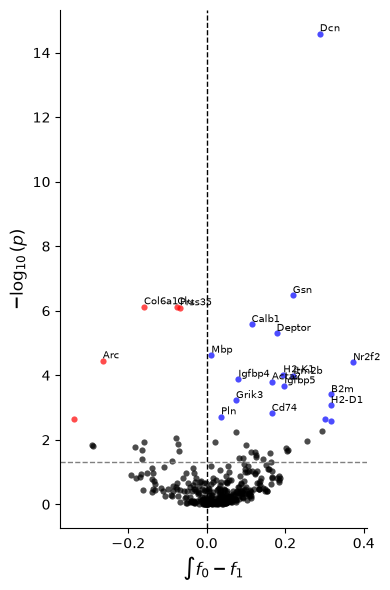

In [18]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=20)

<Axes: xlabel='$\\int f_0 - f_1$', ylabel='$-\\log_{10}(p)$'>

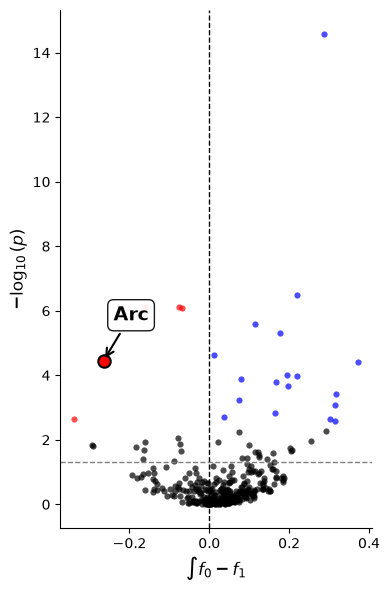

In [21]:
dvg.pl.plot_volcano(adata.varm["dsvg_stats"], n_label=0, highlight_gene="Arc")

<Axes: xlabel='Normalized distance', ylabel='smoothed Arc expression'>

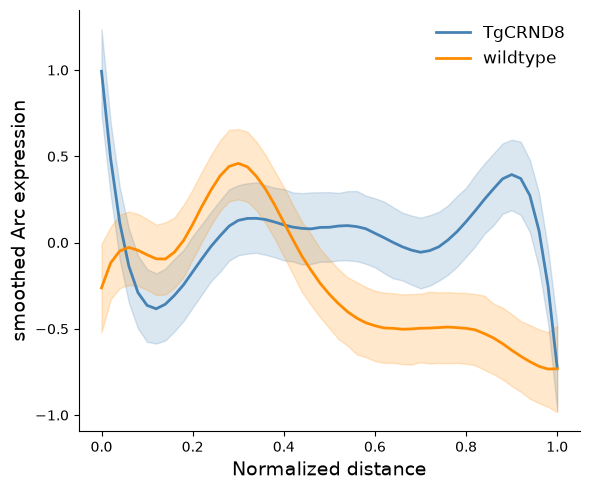

In [23]:
dvg.pl.plot_prediction_curve(adata, gene="Arc")

<Axes: xlabel='gamma_pval', ylabel='count'>

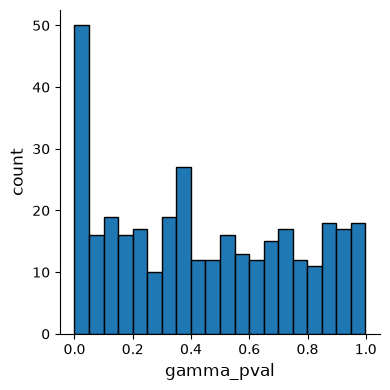

In [25]:
dvg.pl.plot_pvalue_histogram(adata.varm["dsvg_stats"], pvalue="gamma_pval")